# Mô hình một nơ-ron nhân tạo và kiến trúc mạng nơ-ron nhiều lớp (mục 9.1.2)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

Vẽ hình và lưu ảnh.

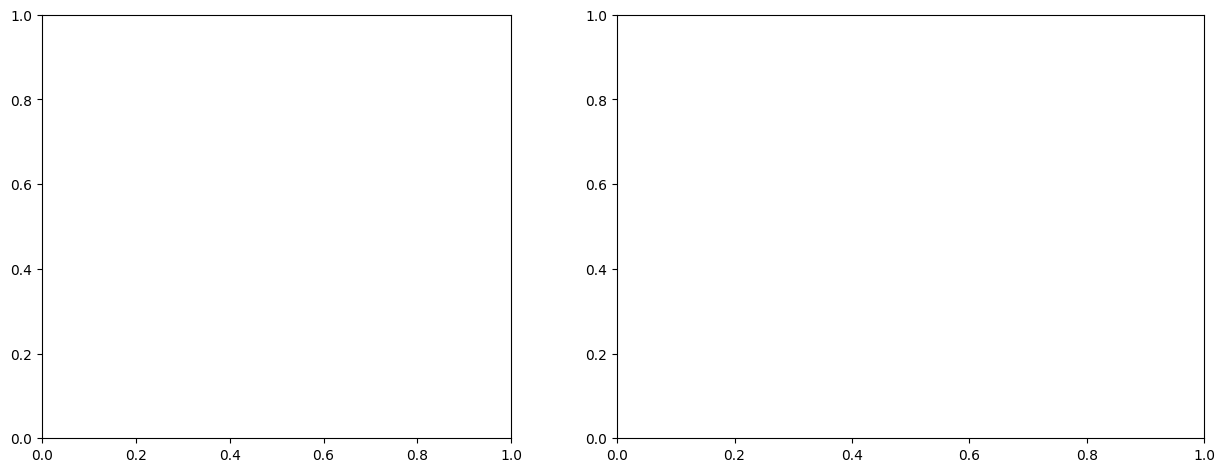

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1, 1.25]})

(a) một nơ-ron: z = w^T x + b, a = f(z)

In [3]:
ax = axes[0]
ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis('off')
inputs = [(1, 5), (1, 3.6), (1, 2.2)]
for (x, y), label, weight in zip(inputs, ['$x_1$', '$x_2$', '$x_d$'], ['$w_1$', '$w_2$', '$w_d$']):
    ax.add_patch(Circle((x, y), 0.35, fc='#E8EEF7', ec='k'))
    ax.text(x, y, label, ha='center', va='center', fontsize=13)
    ax.annotate('', xy=(4.3, 3.3), xytext=(x + 0.35, y), arrowprops=dict(arrowstyle='->', color='gray'))
    ax.text((x + 4.3) / 2, (y + 3.3) / 2 + 0.2, weight, fontsize=12, color='#1F4E9E')
ax.text(1, 2.9, '$\\vdots$', ha='center', fontsize=14)
ax.add_patch(Circle((1, 0.9), 0.35, fc='#FFF3CD', ec='k'))
ax.text(1, 0.9, '1', ha='center', va='center', fontsize=13)
ax.annotate('', xy=(4.3, 3.0), xytext=(1.35, 0.9), arrowprops=dict(arrowstyle='->', color='gray'))
ax.text(2.6, 1.6, '$b$', fontsize=12, color='#1F4E9E')
ax.add_patch(Circle((5, 3.2), 0.75, fc='#D4EDDA', ec='k'))
ax.text(5, 3.2, '$\\Sigma$', ha='center', va='center', fontsize=18)
ax.text(5, 1.9, '$z = \\mathbf{w}^T\\mathbf{x} + b$', ha='center', fontsize=12)
ax.add_patch(FancyBboxPatch((6.5, 2.7), 1.4, 1.0, boxstyle='round,pad=0.1', fc='#F8D7DA', ec='k'))
ax.text(7.2, 3.2, '$f(\\cdot)$', ha='center', va='center', fontsize=15)
ax.text(7.2, 1.9, 'hàm kích hoạt', ha='center', fontsize=11)
ax.annotate('', xy=(6.45, 3.2), xytext=(5.75, 3.2), arrowprops=dict(arrowstyle='->'))
ax.annotate('', xy=(9.5, 3.2), xytext=(8.05, 3.2), arrowprops=dict(arrowstyle='->'))
ax.text(9.0, 3.5, '$a = f(z)$', ha='center', fontsize=13)
ax.set_title('(a) Một nơ-ron nhân tạo', fontsize=13)

Text(0.5, 1.0, '(a) Một nơ-ron nhân tạo')

(b) mạng nhiều lớp 3 - 5 - 4 - 2

In [4]:
ax = axes[1]
ax.set_xlim(-0.5, 7.5); ax.set_ylim(-0.8, 6.7); ax.axis('off')
layers = [3, 5, 4, 2]
x_positions = [0.5, 2.7, 4.9, 7.0]
colors = ['#E8EEF7', '#D4EDDA', '#D4EDDA', '#F8D7DA']
positions = []
for n, x in zip(layers, x_positions):
    top = 2.6 + (n - 1) * 0.55
    positions.append([(x, top - i * 1.1) for i in range(n)])
for left, right in zip(positions[:-1], positions[1:]):
    for p in left:
        for q in right:
            ax.plot([p[0], q[0]], [p[1], q[1]], color='gray', lw=0.6, zorder=0)
for nodes, color in zip(positions, colors):
    for x, y in nodes:
        ax.add_patch(Circle((x, y), 0.3, fc=color, ec='k', zorder=2))
for x, name in zip(x_positions, ['Lớp vào\n$\\mathbf{a}^{(0)} = \\mathbf{x}$', 'Lớp ẩn 1\n$\\mathbf{a}^{(1)}$',
                                 'Lớp ẩn 2\n$\\mathbf{a}^{(2)}$', 'Lớp ra\n$\\mathbf{a}^{(3)} = \\hat{\\mathbf{y}}$']):
    ax.text(x, -0.65, name, ha='center', fontsize=11)
for i, x in enumerate([1.6, 3.8, 5.95]):
    ax.text(x, 5.4, '$\\mathbf{W}^{(%d)}, \\mathbf{b}^{(%d)}$' % (i + 1, i + 1), ha='center', fontsize=11)
ax.annotate('', xy=(6.8, 6.0), xytext=(0.6, 6.0), arrowprops=dict(arrowstyle='->', color='#1F77B4', lw=1.5))
ax.text(3.7, 6.12, 'lan truyền xuôi', ha='center', color='#1F77B4', fontsize=10)
ax.set_title('(b) Mạng nơ-ron 3 – 5 – 4 – 2 (hai lớp ẩn)', fontsize=13)
fig.tight_layout()
fig.savefig(IMAGES / 'neural_network.png', dpi=150)